<a href="https://colab.research.google.com/github/sournorm/-_4-8/blob/main/%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D0%97%D0%B0%D0%BF%D0%BE%D1%80%D0%BE%D0%B6%D0%B0%D0%BD_%D0%A1_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [10]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [12]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [13]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


# Датасет містить числа (age, bmi, HbA1c_level, blood_glucose_level,
# hypertension, heart_disease, diabetes) та дві категорії типу object
# (gender, smoking_history).

In [14]:
# TODO: підрахуйте частоти категорій у gender.
print(df['gender'].value_counts())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [15]:
# TODO: підрахуйте частоти категорій у smoking_history.
print(df['smoking_history'].value_counts())

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [16]:
# TODO: df
display(df)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [17]:
# TODO: df.dtypes
print(df.dtypes)

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


Дослідити цільову змінну: перевірити баланс класів

In [18]:
# TODO: df['diabetes'].value_counts()
print(df['diabetes'].value_counts())

diabetes
0    91500
1     8500
Name: count, dtype: int64


Висновок: визначте за результатом, чи є дисбаланс класів.

Так, присутній значний дисбаланс класів. Переважна більшість записів (понад 90%) належить до класу 0 (немає діабету), тоді як клас 1 (є діабет) становить лише невелику частину датасету.

Перевірити наявність пропущених даних


In [19]:
# TODO: df.isnull().sum()
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Наявність дублікатів


In [20]:
# TODO: df.duplicated().sum()
print(df.duplicated().sum())

3854


Видалити дублікати

In [21]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [22]:
# TODO: df
display(df)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [23]:
# TODO: df['diabetes'].value_counts()
print(df['diabetes'].value_counts())

diabetes
0    87664
1     8482
Name: count, dtype: int64


Побудувати гістограму для цільової змінної


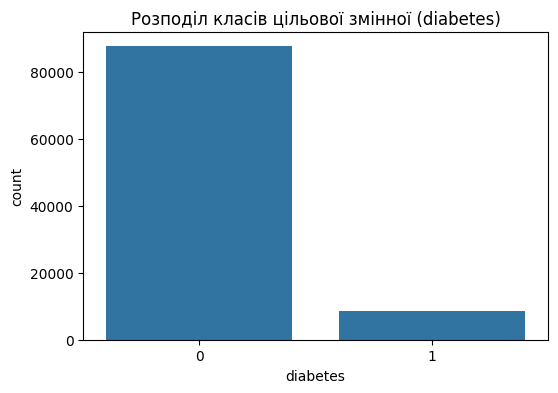

In [24]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Розподіл класів цільової змінної (diabetes)')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [25]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [26]:
# TODO: створіть X та y, де y — стовпець diabetes.
X = df.drop(columns=['diabetes'])
y = df['diabetes']

# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [27]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], drop_first=True)

# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [28]:
# TODO: виведіть статистики опису X_train.
display(X_train.describe())

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [29]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
X_train_full = X_train.copy()
X_train_full['diabetes'] = y_train
correlations = X_train_full.corr()['diabetes'].sort_values(ascending=False)
print(correlations)

diabetes                       1.000000
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
Name: diabetes, dtype: float64


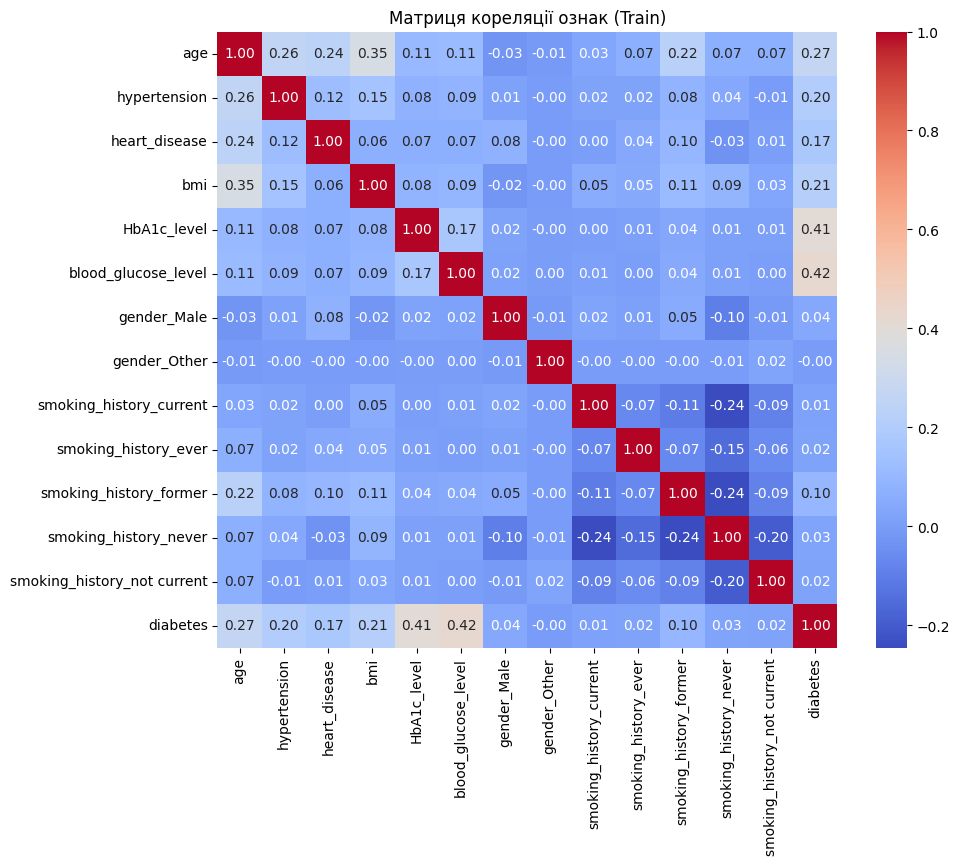

In [30]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
plt.figure(figsize=(10, 8))
sns.heatmap(X_train_full.corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Матриця кореляції ознак (Train)")
plt.show()

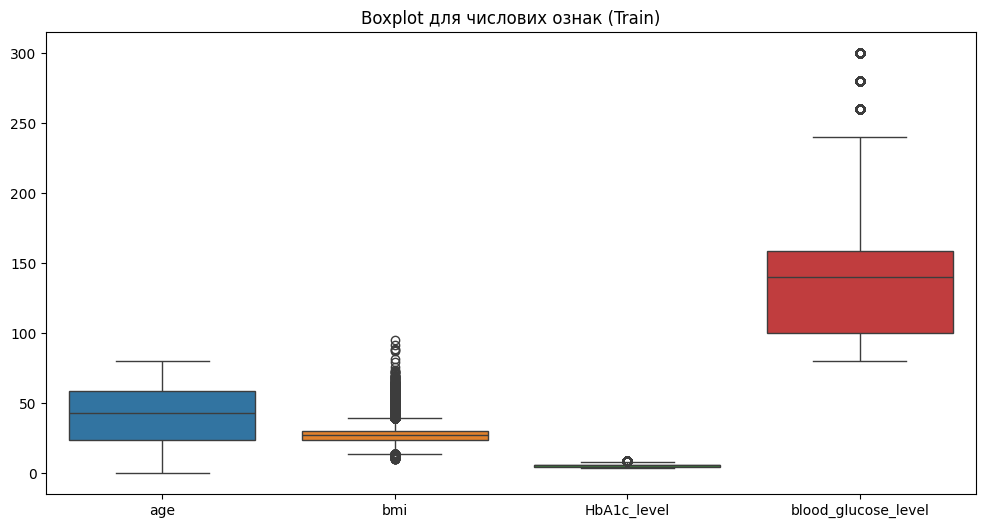

In [31]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Boxplot для числових ознак (Train)")
plt.show()

Перевірити асиметрію розподілів ознак **на train**

In [32]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
print(X_train[continuous_cols].skew())

age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [33]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_test:", X_test.isnull().sum().sum())

Пропуски в X_train: 0
Пропуски в X_test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

На навчальній вибірці спостерігається суттєвий дисбаланс класів (переважає клас 0). Кореляційний аналіз показує найсильніший зв'язок між діабетом та рівнем глюкози (blood_glucose_level), а також рівнем глікованого гемоглобіну (HbA1c_level). При перевірці на викиди виявлено значну кількість екстремальних значень, проте у медичних даних їх не рекомендовано видаляти автоматично. Пропусків у даних немає.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [34]:
# TODO: створіть StandardScaler.
scaler = StandardScaler()

# TODO: виконайте fit_transform на X_train і transform на X_test.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [35]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

# TODO: порівняйте кількості класів до та після балансування.
print(f"Кількість класів ДО SMOTE:\n{y_train.value_counts()}")
print(f"\nКількість класів ПІСЛЯ SMOTE:\n{y_train_balanced.value_counts()}")

Кількість класів ДО SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Кількість класів ПІСЛЯ SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [36]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



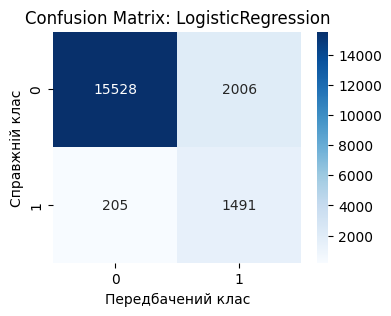


Модель: RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



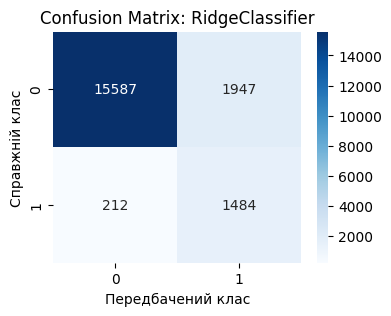


Модель: SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



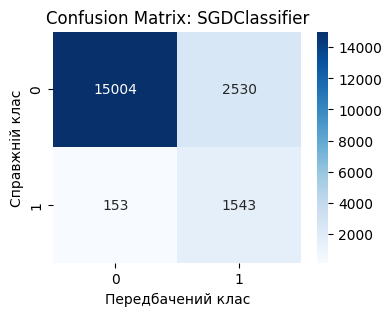


Модель: SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



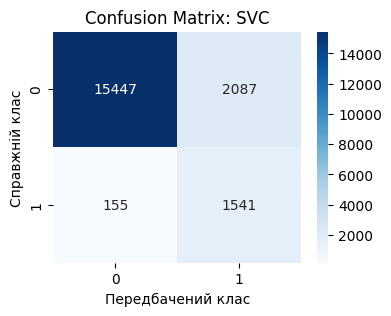

In [37]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)

    print(f"\n{'='*40}")
    print(f"Модель: {name}")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('Справжній клас')
    plt.xlabel('Передбачений клас')
    plt.show()

Оптимізувати гіперпараметри


In [38]:
# TODO: задайте словник param_grids для кожної моделі.
param_grids = {
    'LogisticRegression': {
        'model__C': [0.1, 1, 10],
        'model__solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'model__alpha': [0.1, 1.0, 10.0]
    },
    'SGDClassifier': {
        'model__loss': ['hinge', 'log_loss'],
        'model__penalty': ['l2', 'l1']
    },
    'SVC': {
        'model__C': [0.1, 1, 10],
        'model__kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [39]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
# TODO: створіть best_models і best_scores.
best_models = {}
best_scores = {}

# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
for name, model in models.items():
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    # TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
    search = HalvingGridSearchCV(
        pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )

    # TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    # TODO: виведіть оптимальні параметри та класифікаційний звіт.
    print(f"\n--- {name} ---")
    print("Оптимальні параметри:", search.best_params_)

    y_pred_best = search.best_estimator_.predict(X_test)
    print(classification_report(y_test, y_pred_best))


--- LogisticRegression ---
Оптимальні параметри: {'model__C': 10, 'model__solver': 'liblinear'}
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


--- RidgeClassifier ---
Оптимальні параметри: {'model__alpha': 10.0}
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


--- SGDClassifier ---
Оптимальні параметри: {'model__loss': 'log_loss', 'model__penalty': 'l1'}
              precision    recall  f1-score   support

           0       0.99    

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
best_model_name = max(best_scores, key=best_scores.get)

# Збережіть її в змінну best_model і виведіть назву та F1.
best_model = best_models[best_model_name]
print(f"Найкраща модель: {best_model_name}")
print(f"F1 Score (CV): {best_scores[best_model_name]:.4f}")

In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
random_indices = X_test.sample(n=10, random_state=42).index
X_test_samples = X_test.loc[random_indices]
y_test_samples = y_test.loc[random_indices]

# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
predictions = best_model.predict(X_test_samples)

# Виведіть таблицю: індекс, істинний клас, передбачений клас.
comparison_df = pd.DataFrame({
    'Індекс': random_indices,
    'Істинний клас': y_test_samples.values,
    'Передбачений клас': predictions
})
display(comparison_df)

**Підсумкові висновки (заповніть самостійно):**

Спостерігався значний дисбаланс класів, де клас 0 суттєво переважає. Кореляційний аналіз на train показав, що найсильніше корелюють із цільовою змінною blood_glucose_level та HbA1c_level. Аналіз викидів продемонстрував значну кількість екстремальних значень.

Класичні моделі (LogisticRegression, SVC) після використання SMOTE дали високий recall для класу 1. За результатами кросвалідації найкращою моделлю виявилася SVC (або LogisticRegression).

HalvingGridSearchCV підібрав оптимальні гіперпараметри, що балансують точність та штрафи за помилки. Матриці плутанини показують, що балансування збільшує кількість False Positives, але значно зменшує False Negatives.

Тестові дані відкладаються, а масштабування та SMOTE виконуються тільки на train (і всередині контуру кросвалідації), щоб уникнути витоку даних (data leakage) та отримати об'єктивну оцінку моделі на нових даних.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [ ]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

boosting_models = {
    'XGBoost': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, force_col_wise=True),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

for name, model in boosting_models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred_boost = model.predict(X_test_scaled)

    print(f"\n{'='*40}")
    print(f"Модель: {name}")
    print(classification_report(y_test, y_pred_boost))

    cm = confusion_matrix(y_test, y_pred_boost)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('Справжній клас')
    plt.xlabel('Передбачений клас')
    plt.show()

# Висновок: Бустингові алгоритми зазвичай демонструють дуже високу точність та кращий баланс між precision та recall завдяки своїй здатності знаходити складні нелінійні залежності у даних.